In [1]:
import numpy as np
import matplotlib.pyplot as plt

import os
from statsmodels.stats.weightstats import DescrStatsW

import numpy as np
import scipy.stats as stats

import MDAnalysis as mda

In [2]:
#                           GET RESIDUE INFORMATION FOR PYMOL INSPECTION

def residues(whichprotein, whichresidue):

    if whichprotein == "aac1":
        offset = 1
    elif whichprotein == "ucp1":
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        return 0

    toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/topol.top"
    trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
    u = mda.Universe(toppath, trjpath, topology_format='ITP')

    n_frames = len(u.trajectory)
    n_residues = len(u.select_atoms(f"resname {whichresidue.upper()}").residues)

    #print(u.select_atoms(f"resname {whichresidue.upper()}").residues)
    resseqs = [r.resid for r in u.select_atoms(f"resname {whichresidue.upper()}").residues]

    return resseqs

In [3]:
#Question:
#Does solvation (hydrogen bonding with water) shift the rotamer distribution of threonines on helices?

def heatmap_1(rotamer_data, hbond_data, helix_data, framerates):

    #change in delta-g of adopting the 180 degree rotamer between wet and dry conditions
    ddG_all = []
    #length of simulation for which residue is on a helix
    weights_all = [] 

    for nr in range(rotamer_data.shape[0]):

        helix_rotamer_hbonds = np.zeros((2,3,3))

        for x,y,z,f in zip(helix_data[nr], rotamer_data[nr], hbond_data[nr], framerates):
            helix_rotamer_hbonds[x,y,z]+=1/f

        r_hb = np.array([[helix_rotamer_hbonds[1,0,0],           np.sum(helix_rotamer_hbonds[1,0,1:3])],
                         [np.sum(helix_rotamer_hbonds[1,1:3,0]), np.sum(helix_rotamer_hbonds[1,1:3,1:3])]])

        plot_mat = False
        if plot_mat:
            print(helix_rotamer_hbonds[1])
            plt.imshow(helix_rotamer_hbonds[1])
            plt.ylabel("rotamer")
            plt.xlabel("number of hydrogen bonds")
            plt.yticks([0,1,2],[180, -60, 60])
            plt.xticks([0,1,2],[0,1,2])
            plt.show()
        #print(np.sum(helix_rotamer_hbonds)/5000)

        #calculate effect of hydrogen bonding with water on rotamer free energy
        #we can't do this calculation unless we have sampled in all four states
        if np.all(r_hb>0): 

            dG_rot_dry = -np.log(r_hb[0,0]/r_hb[1,0])
            dG_rot_wet = -np.log(r_hb[0,1]/r_hb[1,1])

            ddG_all.append(dG_rot_wet-dG_rot_dry)
            weights_all.append(np.sum(r_hb))
            #print(np.sum(r_hb)/5000)

            plot_mat_2 = False
            if plot_mat_2:
                print(helix_rotamer_hbonds[1])
                plt.imshow(helix_rotamer_hbonds[1])
                plt.ylabel("rotamer")
                plt.xlabel("number of hydrogen bonds")
                plt.yticks([0,1,2],[180, -60, 60])
                plt.xticks([0,1,2],[0,1,2])
                plt.show()
    # plt.hist(dg_all, weights = weights_all, bins=20, range = (-5,5), density = True)
    # plt.show()
    print(f"raw delta-delta-G values: {ddG_all}")

    confidence_level = 0.95
    # we don't know if the set of delta G values from all relevant protein chemical environments is t-distributed
    # and there is not really any good reason to expect it to be in general
    ci = stats.t.interval(confidence_level, df=len(ddG_all)-1, loc=np.mean(ddG_all), scale=np.std(ddG_all, ddof=1) / np.sqrt(len(ddG_all)))
    print(f"single-protein {confidence_level*100}% t test confidence interval: {ci}")

    bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
    print(f"single-protein {confidence_level*100}% bootstrap confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")

    #MG meeting list [see copy in other document; this one is out of date]
    #TODO-N/A; also get a spearman CI - this does not appear to be the right test for this purpose
    #TODO-done: try bootstrapping - this yields smaller 95% CIs than the t test
    # for our small sample sizes this may actually be worse:  Am Stat. 2015 Dec 29;69(4):371–386. doi: 10.1080/00031305.2015.1089789 
    # consider the example of 10 data points at x=-0.1 and 10 data points at x=-1.1. 
    #   Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
    #   However computing the standard deviation 
    #TODO try giving each site a fixed solvation assignment and then testing the 
    # difference of means between the deltaG +-60/180 for solvated and non-solvated ones 
    #TODO write code to print the delta G of different residues by protein and pdb index
    #TODO multiply delta G value based on hbond frac in "solvated" helices and non-solvated ones 
    # to get actual rotamer delta-G for membrane and water helices given the imperfect correspondence between solvent and hydrogen bond formation
    #TODO-done - look at transitions: everything has at least a few rotamer transitions each way even in one short segment so nothing is so kinetically trapped
    # that it needs to be thrown out
    
    return ddG_all, weights_all


In [4]:
def hist_fixed_class(rotamer_data, hbond_data, helix_data, resseqs):

    dG_all = []
    hbond_t_frac_all = []

    resseqs_out = []

    helicity_thresh = 0.75

    rotamer_data_180deg = np.where(rotamer_data==0, 1, 0)

    for nr in range(rotamer_data.shape[0]):
        if np.sum(helix_data[nr])/len(helix_data[nr]) >= helicity_thresh:
            if np.sum(rotamer_data_180deg[nr]) > 0 and (len(rotamer_data_180deg[nr])-np.sum(rotamer_data_180deg[nr])) > 0:
                
                dG = -np.log(np.sum(rotamer_data_180deg[nr])/(len(rotamer_data_180deg[nr])-np.sum(rotamer_data_180deg[nr])))
                dG_all.append(dG)
                hbond_t_frac = np.sum(hbond_data[nr])/len(hbond_data[nr])
                hbond_t_frac_all.append(hbond_t_frac)
                print(hbond_t_frac)

                resseqs_out.append(resseqs[nr])

    return dG_all, hbond_t_frac_all, resseqs_out

In [5]:
def load_process(analysis_method, resn):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    # dG_dry_all = []
    # dG_wet_all = []
    # dG_interfacial_all = []
    dG_all = []
    hbond_t_frac_all = []

    resseq_all = []
    prot_all = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        print("---------------------------------------------: " +protein)
        rotamer_data = []
        hbond_data = []
        helix_data = []
        framerates = []

        resseqs = residues(protein, resn)

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"

                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file):
                        rotamer_data.append(np.load(rotamer_file))
                        hbond_data.append(np.load(hbond_file))
                        helix_data.append(np.load(secstr_file))
                        framerates.append(framerate*np.ones(rotamer_data[-1].shape[1]))

        #residue level variation is much larger than simulation-level variation, 
        # so standard deviations and errors are computed across residues rather than simulations
        rotamer_data = np.concatenate(rotamer_data, axis = 1)
        hbond_data = np.concatenate(hbond_data, axis = 1)
        helix_data = np.concatenate(helix_data, axis = 1)
        framerates = np.concatenate(framerates, axis = 0)

        dG, hbond_t_frac, resseqs = analysis_method(rotamer_data, hbond_data, helix_data, resseqs)

        print(dG)
        print(hbond_t_frac)

        dG_all.append(dG)
        hbond_t_frac_all.append(hbond_t_frac)
        resseq_all += resseqs
        prot_all += [protein for x in range(len(resseqs))]

        # dG_dry, dG_wet, dG_interfacial = analysis_method(rotamer_data, hbond_data, helix_data)
        # dG_dry_all.append(dG_dry)
        # dG_wet_all.append(dG_wet)
        # dG_interfacial_all.append(dG_interfacial)

    # print(list(dG_wet_all))
    # print(list(dG_dry_all))
    # print(list(dG_interfacial_all))

    # dG_dry_all = np.concatenate(dG_dry_all)
    # dG_wet_all = np.concatenate(dG_wet_all)
    # dG_interfacial_all = np.concatenate(dG_interfacial_all)
    print(dG_all)
    print(hbond_t_frac_all)

    dG_all = np.concatenate(dG_all)
    hbond_t_frac_all = np.concatenate(hbond_t_frac_all)

    return dG_all, hbond_t_frac_all, prot_all, resseq_all


---------------------------------------------: ucp1


/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


0.08680722967335662
0.4149473622425236
0.7778229644008603
0.759010888112797
0.007752067986768239
0.21486518780631989
0.6775953076719898
0.8603453841864521
0.7459803703719232
0.004502823698101183
0.007051908249726435
0.5621150693661249
0.5805833546455809
0.8450131437172194
[7.766651809173982, 3.6146490912575726, 7.123895195333997, 2.024421769717834, 7.370931487676962, 5.927485280704487, 5.363607347624965, 1.051104909077025, 5.638123283774958, 8.430734109436084, 8.980872698825273, 6.60009303260951, 8.85569278332792, 2.4994897036341595]
[0.08680722967335662, 0.4149473622425236, 0.7778229644008603, 0.759010888112797, 0.007752067986768239, 0.21486518780631989, 0.6775953076719898, 0.8603453841864521, 0.7459803703719232, 0.004502823698101183, 0.007051908249726435, 0.5621150693661249, 0.5805833546455809, 0.8450131437172194]
---------------------------------------------: aac1
0.008630434608323379
0.6811349041552757
0.007956996143763079
0.15321526781204653
0.4865232135842159
0.317458090481268
0.

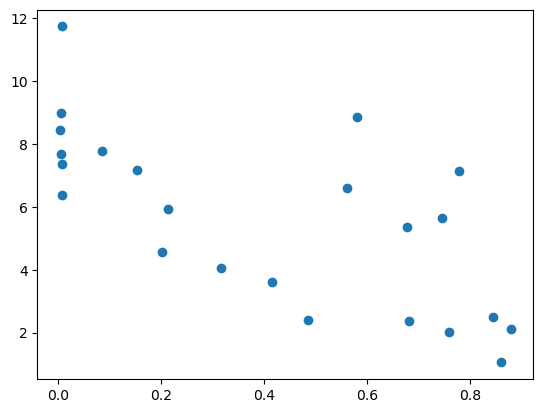

In [20]:
resn = "thr"
dG_all, hbond_t_frac_all, prot_all, resseq_all = load_process(hist_fixed_class, resn)

plt.scatter(hbond_t_frac_all, dG_all)
print(f"using {len(dG_all)} total residues")

using 23 total residues


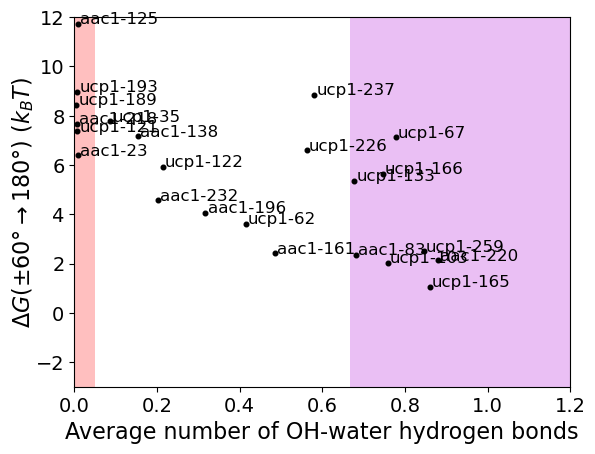

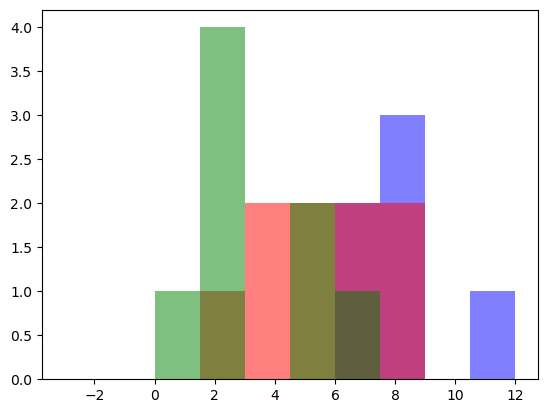

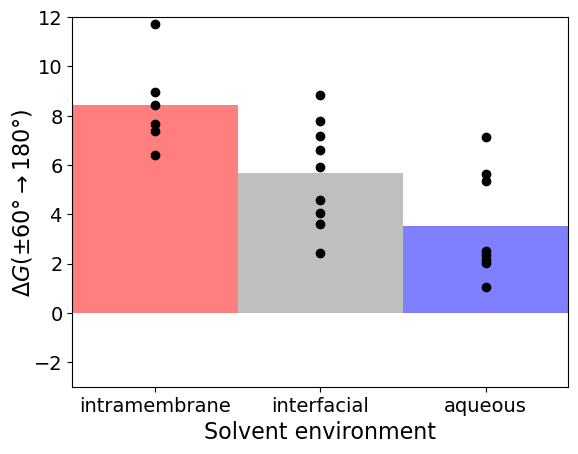

wet vs dry residue t test for difference of means:
TtestResult(statistic=4.424169977980111, pvalue=0.0008295099773737089, df=12.0)
2-protein t test 95.0%  confidence interval for ddG: (2.49, 7.33)
2-protein bootstrap 95.0% confidence interval for ddG: (3.01, 6.94)
ddG = 4.91 kT
slope -5.722220110540409
-5.006666162824722


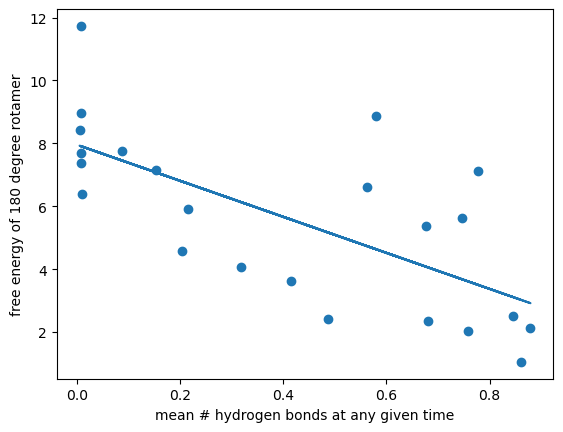

2-protein 95.0% bootstrap confidence interval for linreg slope: (-8.051571120292746, -3.2008590088820843)


In [21]:
#plt.figure(figsize=(5,5), dpi=600)
fsz = 16

#plt.scatter(hbond_t_frac_all, dG_all, s=8, color="black")
print(f"using {len(dG_all)} total residues")

label_points_by_protein = True
point_size = 11

if label_points_by_protein:
    for p, r, w, g in zip(prot_all, resseq_all, hbond_t_frac_all, dG_all):
        plt.annotate(f"{p}-{r}", (w+0.005, g), fontsize=12) #the protein was formerly also included in the point label
        plt.scatter(w, g, s=point_size, color="black")

else:    
    #these are dummy variables used to generate the legend, not a setting to toggle between plot formats
    aac1label = False
    ucp1label = False
    for p, r, w, g in zip(prot_all, resseq_all, hbond_t_frac_all, dG_all):
        plt.annotate(f"{r}", (w+0.005, g), fontsize=12) #the protein was formerly also included in the point label
        if p == "aac1":
            if not aac1label:
                label = "AAC1"
                aac1label = True
            else:
                label = "_nolegend_"
            plt.scatter(w, g, s=point_size, color="black", label=label)
        else:
            if not ucp1label:
                label = "UCP1"
                ucp1label = True
            else:
                label = "_nolegend_"
            plt.scatter(w, g, s=point_size, color="black", facecolors='none', label=label)

    plt.legend(fontsize=14, loc="upper right", markerscale=1.5, handletextpad=0.5, labelspacing=0.2)

plt.xlabel("Average number of OH-water hydrogen bonds", fontsize=fsz)
plt.ylabel(r"$\Delta G(±60\degree\rightarrow 180\degree)\ (k_BT)$", fontsize=fsz, labelpad=0)
#plt.ylabel(r"Free energy of 180 degree rotamer, $\Delta G_{rot|i}$ (kT)")
plt.xlim(0,1.2)
plt.ylim(-3,12)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.fill_between((0, 0.05), -3, 12, color="red", alpha=0.25, linewidth=0, zorder=0)
#plt.fill_between((2/3, 1.2), -3, 12, color="blue", alpha=0.25, linewidth=0, zorder=0) #for previous color scheme
plt.fill_between((2/3, 1.2), -3, 12, color=[234/255, 191/255, 244/255], alpha=1, linewidth=0, zorder=0)

# plt.axvline(0.05, color="red")
# plt.axvline(2/3, color="red")
version = 4
plt.savefig(f"figures/rotamer_solvation_scatter_{resn}_v{version}.png", dpi=600, bbox_inches='tight')
plt.savefig(f"figures/rotamer_solvation_scatter_{resn}_v{version}.svg", format="svg", bbox_inches='tight')

plt.show()


#---------------------------------------------------------------------------------------------------

#67 and 166 on short helices in ucp1 are stabilized in the +60 rotamer by an ordered water bound to a salt bridge and tyrosine. 
# 133, 226, and 237 are wedged between helices. However resi 122 and 35 are stuck between helices but are not outliers.
# since Tarun's analysis does not know which way the residues are facing, we should include these residues in our analysis 
# since ones in analogous states would be included in his analysis 

dry_residues = [g for g, hf in zip(dG_all, hbond_t_frac_all) if hf <= 0.05]
inter_residues = [g for g, hf in zip(dG_all, hbond_t_frac_all) if hf > 0.05 and hf < 2/3]
wet_residues = [g for g, hf in zip(dG_all, hbond_t_frac_all) if hf >= 2/3]

plt.hist(dry_residues, alpha = 0.5, range=[-3,12], bins=10, color="blue")
plt.hist(inter_residues, alpha = 0.5, range=[-3,12], bins=10, color="red")
plt.hist(wet_residues, alpha = 0.5, range=[-3,12], bins=10, color="green")
plt.show()


#---------------------------------------------------------------------------------------------------

bar_width = 1

resdata = (dry_residues, inter_residues, wet_residues)
colors = ["red", "grey", "blue"]
means = [np.mean(rs) for rs in resdata]
xplot = [1, 2, 3]
for x, m, c, rd in zip(xplot, means, colors, resdata):
    plt.bar(x, m, width=bar_width, color = c, alpha=0.5)
    plt.scatter([x for i in range(len(rd))], rd, color="black")
#plt.boxplot((dry_residues, inter_residues, wet_residues))

plt.xlim(0.5, 3.5)
plt.xticks([1,2,3], ["intramembrane", "interfacial", "aqueous"], fontsize=14)
plt.xlabel("Solvent environment", fontsize=fsz)

plt.ylim(-3, 12)
plt.yticks(fontsize=14)
plt.ylabel(r"$\Delta G(±60\degree\rightarrow 180\degree)$", fontsize=fsz, labelpad=0)
#plt.ylabel(r"Free energy of 180 degree rotamer, $\Delta G_{rot|i}$ (kT)")

np.save(f"figures/mean_{resn}_rotamer_DeltaG_by_solvation.npy", means)

#make nan-padded data array
datapoints = np.ones((3, max([len(rd) for rd in resdata])))*np.nan
for i, rd in enumerate(resdata):
    datapoints[i,:len(rd)] = rd

np.save(f"figures/{resn}_rotamer_DeltaG_by_solvation.npy", datapoints)

plt.savefig(f"figures/rotamer_solvation_barplot_{resn}.png", dpi=600, bbox_inches='tight')

plt.show()


#---------------------------------------------------------------------------------------------------

print("wet vs dry residue t test for difference of means:")
print(stats.ttest_ind(dry_residues, wet_residues))
# print(stats.ttest_ind(dry_residues, inter_residues))
# print(stats.ttest_ind(wet_residues, inter_residues))

confidence_level = 0.95

ci = stats.ttest_ind(dry_residues, wet_residues).confidence_interval(confidence_level=confidence_level)
print(f"2-protein t test {confidence_level*100}%  confidence interval for ddG: ({ci.low:.3}, {ci.high:.3})")

def delta_mean(sample1, sample2, axis=-1):
    mean1 = np.mean(sample1, axis=axis)
    mean2 = np.mean(sample2, axis=axis)
    return mean1 - mean2

bootstrap_result = stats.bootstrap(data=(dry_residues,wet_residues), statistic=delta_mean, n_resamples=9999, confidence_level=confidence_level)
print(f"2-protein bootstrap {confidence_level*100}% confidence interval for ddG: ({bootstrap_result.confidence_interval.low:.3}, {bootstrap_result.confidence_interval.high:.3})")


dG_wetdry = np.mean(dry_residues)-np.mean(wet_residues)
print(f"ddG = {dG_wetdry:.3} kT")

wet_residue_hf = np.mean([hf for g, hf in zip(dG_all, hbond_t_frac_all) if hf >= 2/3])
dry_residue_hf = np.mean([hf for g, hf in zip(dG_all, hbond_t_frac_all) if hf < 0.05])

T = 310.15 #K
kB = 1.380649*10**-23 #J/K
NA = 6.022*10**23 #1/mol

G_hb_wat = 0.480 #kcal/mol, from J. Am. Chem. Soc. 2000, 122, 33, 8037–8041 https://doi.org/10.1021/ja000459t
G_hb_mem = 5 #kcal/mol, from J Am Chem Soc. 2017 Jul 10;139(31):10742–10749. doi: 10.1021/jacs.7b04819 

G_hb = G_hb_wat

Jkc = 4184 #joules per kcal

hbond_strength_kt = G_hb*Jkc/(NA*kB*T) #kT
# print(hbond_strength_kt)
# print((wet_residue_hf-dry_residue_hf)*hbond_strength_kt)

#moved to other notebook
# #Tieleman and Macallum measure the free energy of bringing ethanol from water to the middle of a membrane http://www.jgp.org/cgi/doi/10.1085/jgp.200709745
# #this is analogous to the difference between the free energy of the 180 degree rotamers in those two locations
# #they report a value of 13.9 kJ/mol.
# print("180 degree transfer free energy:")
# print(13.9*1000/(NA*kB*T))

# #hessa von heijne transfer free energy
# print(0.52*Jkc/(NA*kB*T))

#linear regression
linreg = True
if linreg:
    slope, intercept, r, p, std_err = stats.linregress(hbond_t_frac_all, dG_all)
    print(f"slope {slope}")
    print(slope*(max(hbond_t_frac_all)-min(hbond_t_frac_all)))

    def myfunc(x):
        return slope * x + intercept

    mymodel = list(map(myfunc, hbond_t_frac_all))

    plt.scatter(hbond_t_frac_all, dG_all)
    plt.plot(hbond_t_frac_all, mymodel)
    plt.xlabel("mean # hydrogen bonds at any given time")
    plt.ylabel("free energy of 180 degree rotamer")
    plt.show() 

    #boostrap slope with linear regression
    def linreg_slope(sample_hb, sample_G):
        slope, intercept, r, p, std_err = stats.linregress(sample_hb, sample_G)
        return slope

    #note that paired=true is needed here
    bootstrap_result = stats.bootstrap(data=(hbond_t_frac_all, dG_all), statistic=linreg_slope, n_resamples=9999, paired=True, confidence_level=confidence_level)
    print(f"2-protein {confidence_level*100}% bootstrap confidence interval for linreg slope: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")


In [8]:

#Tieleman and Macallum measure the free energy of bringing ethanol from water to the middle of a membrane http://www.jgp.org/cgi/doi/10.1085/jgp.200709745
#this is analogous to the difference between the free energy of the 180 degree rotamers in those two locations
#they report a value of 13.9 kJ/mol.


In [9]:
#the other notebook measures P(180|hbond)/P(180|no hbond) = A
#this one measures P(180|solvent exposed)/P(180|membrane exposed) = B

#P(180|solvent exposed) = P(180|hbond)*P(hbond | solvent exposed) + P(180|no hbond)*P(no hbond | solvent exposed) =~ P(180|hbond)
#P(180|membrane exposed) = P(180|hbond)*P(hbond | membrane exposed) + P(180|no hbond)*P(no hbond | membrane exposed) 
# =~ P(180|hbond)*P(hbond | membrane exposed) + P(180|no hbond)
#note that both terms of this latter equation are small

#B = P(180|solvent exposed)/P(180|membrane exposed) =~ P(180|hbond)/(P(180|hbond)*P(hbond | membrane exposed) + P(180|no hbond))
#1/B =~ 1/A + P(hbond | membrane exposed) # A is generally large so both of these terms are small
#so B deviates from A by an amount proportional to the energetic cost of bringing water into the membrane



#VV WRONG VERSION VV
#B = A*P(hbond|solvent exposed)/P(no hbond|membrane exposed)
#in theory A should be close to B because both the numerator and denominator of the conversion factor are close to 1


In [10]:
resn = "thr"
dG_dry_all, dG_wet_all, dG_interfacial_all = load_process(hist_fixed_class, resn)
plt.hist(dG_dry_all, alpha=1/3)
plt.hist(dG_wet_all, alpha=1/3)
plt.hist(dG_interfacial_all, alpha=1/3)

print(f"using {len(dG_dry_all)+len(dG_wet_all)+len(dG_interfacial_all)} total residues")



---------------------------------------------: ucp1


/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


0.08680722967335662
0.4149473622425236
0.7778229644008603
0.759010888112797
0.007752067986768239
0.21486518780631989
0.6775953076719898
0.8603453841864521
0.7459803703719232
0.004502823698101183
0.007051908249726435
0.5621150693661249
0.5805833546455809
0.8450131437172194
[7.766651809173982, 3.6146490912575726, 7.123895195333997, 2.024421769717834, 7.370931487676962, 5.927485280704487, 5.363607347624965, 1.051104909077025, 5.638123283774958, 8.430734109436084, 8.980872698825273, 6.60009303260951, 8.85569278332792, 2.4994897036341595]
[0.08680722967335662, 0.4149473622425236, 0.7778229644008603, 0.759010888112797, 0.007752067986768239, 0.21486518780631989, 0.6775953076719898, 0.8603453841864521, 0.7459803703719232, 0.004502823698101183, 0.007051908249726435, 0.5621150693661249, 0.5805833546455809, 0.8450131437172194]
---------------------------------------------: aac1
0.008630434608323379
0.6811349041552757
0.007956996143763079
0.15321526781204653
0.4865232135842159
0.317458090481268
0.

ValueError: too many values to unpack (expected 3)

In [ ]:
    
def compile_results(ddG_all, weights_all, resn):

    plot_with_alldata = False
    if plot_with_alldata:
        plt.show()
        plt.scatter(weights_all, ddG_all)

        plt.show()
        plt.hist(ddG_all, weights = weights_all, bins=20, range = (-5,5), density = True)

        confidence_level = 0.99
        # ci = stats.t.interval(confidence_level, df=len(dg_all)-1, loc=np.mean(dg_all), scale=np.std(dg_all, ddof=1) / np.sqrt(len(dg_all)))
        # print(f"{confidence_level*100}% confidence interval: {ci}")
        bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
        print(f"single-protein {confidence_level*100}% confidence interval: {bootstrap_result.confidence_interval}")

    ddG_mostlyhelical = []
    weights_mostlyhelical = []

    #print(weights_all)

    for d, w in zip(ddG_all, weights_all):
        if w >= max(weights_all)*1/2:
            ddG_mostlyhelical.append(d)
            weights_mostlyhelical.append(w)

    print("---------------------------------------------: overall")
    
    print(f"data for {len(ddG_mostlyhelical)} residues")
    print(f"each residue used below has at least {min(weights_mostlyhelical)/5000} microseconds of aggregate data in a helix")
    print(f"water H-bonding favors 180 degree rotamer by {-np.mean(ddG_mostlyhelical):.2f} kT on helices")

    printrange=False
    if printrange:
        print(min(ddG_mostlyhelical))
        print(max(ddG_mostlyhelical))

    plt.show()
    plt.hist(ddG_mostlyhelical, bins=14, range = (-3.5,3.5), density = True)
    plt.xlim(-3.5,3.5)
    plt.ylim(0,0.5)
    plt.xlabel("free energy change of 180 degree\nrotamer upon water H-bonding (kT)")
    plt.ylabel("probability density")
    plt.savefig(f"figures/{resn}-rotamer-free-energy.png", bbox_inches="tight", dpi=600)

    confidence_level = 0.95
    ci = stats.t.interval(confidence_level, df=len(ddG_mostlyhelical)-1, loc=np.mean(ddG_mostlyhelical), scale=np.std(ddG_mostlyhelical, ddof=1) / np.sqrt(len(ddG_mostlyhelical)))
    print(f"2-protein combined {confidence_level*100}% t-test confidence interval: {ci}")
    bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
    print(f"2-protein combined {confidence_level*100}% bootstrap confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")


In [ ]:
resn = "thr"
ddG_all, weights_all = load_process(heatmap_1, resn)
compile_results(ddG_all, weights_all, resn)

In [ ]:
####################################################################################
#                                 TRIMMINGS BELOW
####################################################################################

In [ ]:
resn2 = "thr"
print(np.load(f"figures/mean_{resn2}_rotamer_DeltaG_by_solvation.npy"))
print(np.load(f"figures/{resn2}_rotamer_DeltaG_by_solvation.npy"))